# 2. Density valleys (kernel density estimate)

**Idea:** smooth the focal lengths with a kernel density estimate (KDE). Each peak is a focal length that many photos share, and each valley between peaks is a natural place to split the groups. The KDE bandwidth is the smoothing scale, and it is a reasonable starting `eps`.

**Method:** `scipy.stats.gaussian_kde` with Scott's rule bandwidth. Valleys are the local minima of the density, found with `find_peaks`.

**Reading the plot:** red dotted lines mark the valleys (group boundaries). The bandwidth in mm is printed for reference only. It is a smoothing scale for the density curve, not a measured gap between photos, so it is **not** a DBSCAN `eps` candidate.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().parent  # notebooks are run from the notebooks/ folder
if not (ROOT / "focal_data.py").is_file():
    raise FileNotFoundError(f"focal_data.py not found in {ROOT}; run from notebooks/")
sys.path.insert(0, str(ROOT))

from focal_data import load_focal_mm

DIRECTORY, DEPTH = r"D:\DCIM", 1
focal = load_focal_mm(DIRECTORY, DEPTH)
print(f"{len(focal)} images, focal length {focal.min():.0f}-{focal.max():.0f} mm, {len(np.unique(focal))} distinct values")


885 images, focal length 18-135 mm, 87 distinct values


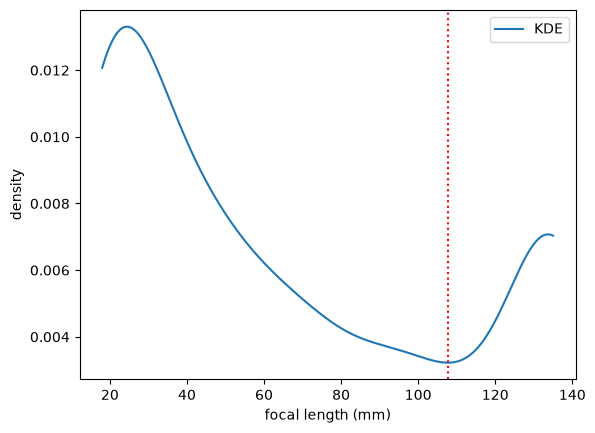

Valleys (group boundaries, mm): [107.7]
KDE bandwidth (smoothing scale, not an eps candidate) = 11.16 mm


In [2]:
from scipy.signal import find_peaks
from scipy.stats import gaussian_kde

kde = gaussian_kde(focal)  # Scott's rule bandwidth
grid = np.linspace(focal.min(), focal.max(), 2000)
density = kde(grid)

valleys = find_peaks(-density)[0]
cuts = grid[valleys]
eps = kde.factor * focal.std(ddof=1)  # bandwidth in mm

plt.plot(grid, density, label="KDE")
for c in cuts:
    plt.axvline(c, ls=":", color="red")
plt.xlabel("focal length (mm)")
plt.ylabel("density")
plt.legend()
plt.show()
print(f"Valleys (group boundaries, mm): {np.round(cuts, 1).tolist()}")
print(f"KDE bandwidth (smoothing scale, not an eps candidate) = {eps:.2f} mm")

## What to take away
The valleys show where the groups split. The bandwidth only controls how smooth the density curve looks, so it does not set DBSCAN's `eps`. Use the gap-based methods (notebooks 01, 03 and 04) for `eps`. Many tiny valleys around single-value spikes mean the bandwidth is too narrow for the spacing of values.